In [1]:
import pandas as pd
df=pd.read_csv('covid19_clinical_trials_feature_engineered.csv')

In [2]:
df[df['Start Date'] < '2019-01-01'].shape

(82, 29)

In [3]:
import duckdb

con = duckdb.connect()  # in-memory database

con.execute("CREATE TABLE trials AS SELECT * FROM 'covid19_clinical_trials_feature_engineered.csv'")
con.execute("CREATE TABLE conditions AS SELECT * FROM 'conditions.csv'")
con.execute("CREATE TABLE interventions AS SELECT * FROM 'interventions.csv'")
con.execute("CREATE TABLE funders AS SELECT * FROM 'funders.csv'")
con.execute("CREATE TABLE phases AS SELECT * FROM 'phases.csv'")

# sanity check — list tables and row counts
print(con.execute("SHOW TABLES").df())
print(con.execute("SELECT COUNT(*) FROM trials").df())

            name
0     conditions
1        funders
2  interventions
3         phases
4         trials
   count_star()
0          5783


In [4]:
query = """
SELECT 
    p.phase,
    COUNT(DISTINCT t."NCT Number") AS trial_count,
    ROUND(AVG(t.trial_duration_days), 1) AS avg_duration_days
FROM trials t
JOIN phases p ON t."NCT Number" = p.nct_number
GROUP BY p.phase
ORDER BY trial_count DESC
"""

result = con.execute(query).df()
print(result)

            phase  trial_count  avg_duration_days
0  Not Applicable         3815              406.2
1         Phase 2         1077              378.3
2         Phase 3          650              394.1
3         Phase 1          426              360.6
4         Phase 4          161              339.4
5   Early Phase 1           46              382.2


In [5]:
query = """
SELECT 
    c.condition,
    COUNT(DISTINCT t."NCT Number") AS trial_count,
    ROUND(AVG(t."Enrollment"), 0) AS avg_enrollment
FROM trials t
JOIN conditions c ON t."NCT Number" = c.nct_number
WHERE c.condition != 'covid-19'
GROUP BY c.condition
HAVING COUNT(DISTINCT t."NCT Number") >= 20
ORDER BY trial_count DESC
LIMIT 24
"""

result = con.execute(query).df()
print(result)

                              condition  trial_count  avg_enrollment
0   acute respiratory distress syndrome          211           830.0
1                               anxiety          100          3712.0
2                            depression           85          4003.0
3                      pneumonia, viral           82           410.0
4                              diabetes           70         32680.0
5                             pneumonia           70          1816.0
6                                cancer           60          6980.0
7                   respiratory failure           46           352.0
8                      critical illness           43          8547.0
9                                stress           40           679.0
10                      quality of life           37          3412.0
11                              healthy           34           991.0
12              cardiovascular diseases           33          7937.0
13                  acute kidney i

In [6]:
query = """
SELECT t."NCT Number", t."Title", t."Enrollment"
FROM trials t
JOIN conditions c ON t."NCT Number" = c.nct_number
WHERE c.condition = 'obesity'
ORDER BY t."Enrollment" DESC
LIMIT 30
"""
print(con.execute(query).df())

     NCT Number                                              Title  Enrollment
0   NCT02788903     A Patient-Centered PaTH to Addressing Diabetes   2000000.0
1   NCT04409197  Evaluation of Changes in Weight, Sleep, and Ot...      4789.0
2   NCT04735835  Personalized Responses to Dietary Composition ...      3000.0
3   NCT03983733  PREDICT 2: Personalized Responses to Dietary C...      1139.0
4   NCT04802044  COVID-19, Aging, and Cardiometabolic Risk Fact...       500.0
5   NCT03260140                         DVD Lifestyle Intervention       500.0
6   NCT04530617  Camostat and Artemisia Annua vs Placebo in COV...       360.0
7   NCT04799132  Association Between Body Mass Index and HFNC T...       303.0
8   NCT03069690  Optimizing Health From Pregnancy Through One Y...       300.0
9   NCT04425213  Obesity and Mortality of Critically Ill Patien...       250.0
10  NCT04714892  Mechanisms Underlying Individual Variations of...       248.0
11  NCT04507867  Effect of a Nss to Reduce Complicat

In [7]:
query = """
SELECT 
    c.condition,
    COUNT(DISTINCT t."NCT Number") AS trial_count,
    ROUND(MEDIAN(t."Enrollment"), 0) AS median_enrollment,
    ROUND(AVG(t."Enrollment"), 0) AS avg_enrollment
FROM trials t
JOIN conditions c ON t."NCT Number" = c.nct_number
WHERE c.condition != 'covid-19'
GROUP BY c.condition
HAVING COUNT(DISTINCT t."NCT Number") >= 20
ORDER BY trial_count DESC
"""
print(con.execute(query).df())

                              condition  trial_count  median_enrollment  \
0   acute respiratory distress syndrome          211               80.0   
1                               anxiety          100              300.0   
2                            depression           85              500.0   
3                      pneumonia, viral           82              113.0   
4                             pneumonia           70              129.0   
5                              diabetes           70              192.0   
6                                cancer           60              400.0   
7                   respiratory failure           46               63.0   
8                      critical illness           43              230.0   
9                                stress           40              151.0   
10                      quality of life           37              150.0   
11                              healthy           34              300.0   
12              cardiovas

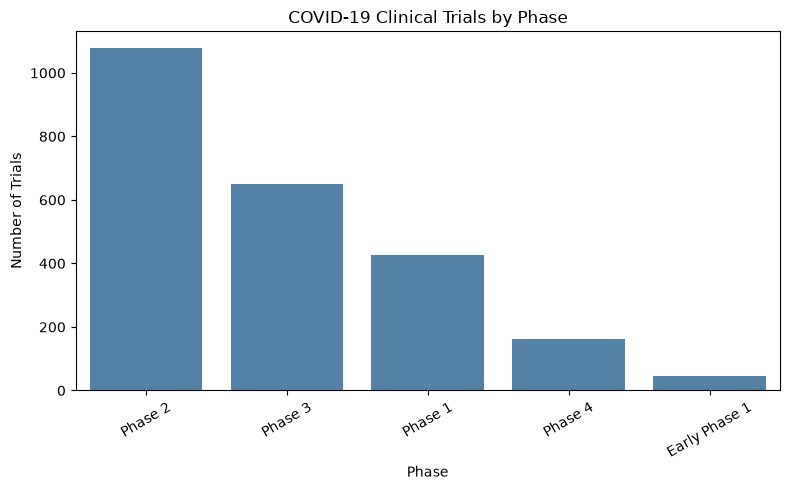

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

phase_data = con.execute("""
    SELECT p.phase, COUNT(DISTINCT t."NCT Number") AS trial_count
    FROM trials t
    JOIN phases p ON t."NCT Number" = p.nct_number
    WHERE p.phase != 'Not Applicable'
    GROUP BY p.phase
    ORDER BY trial_count DESC
""").df()

plt.figure(figsize=(8, 5))
sns.barplot(data=phase_data, x='phase', y='trial_count', color='steelblue')
plt.title('COVID-19 Clinical Trials by Phase')
plt.xlabel('Phase')
plt.ylabel('Number of Trials')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
query = """
SELECT "NCT Number", "Title", "Start Date"
FROM trials
WHERE "Start Date" < '2019-01-01'
ORDER BY "Start Date"
"""
print(con.execute(query).df())

     NCT Number                                              Title Start Date
0   NCT04322786  The Use of Angiotensin Converting Enzyme Inhib... 1998-01-01
1   NCT01087333  Collection of Human Samples to Study Hairy Cel... 2010-03-02
2   NCT03925272  Creation of a Prospective Cohort of Healthy an... 2011-02-02
3   NCT01306084  Viral Infections in Healthy and Immunocompromi... 2011-03-15
4   NCT04430231  Does Delaying Curative Surgery for Colorectal ... 2012-01-01
..          ...                                                ...        ...
77  NCT03680274         Lessening Organ Dysfunction With VITamin C 2018-11-08
78  NCT03651622  ACT1ON Phase 2 (SMART Pilot) and Phase 3 (Effi... 2018-11-12
79  NCT03684980  LTA Pilot Study of Glucarpidase in Patients Wi... 2018-11-14
80  NCT03944447  Outcomes Mandate National Integration With Can... 2018-12-01
81  NCT03821402  Efficacy and Safety of DaxibotulinumtoxinA for... 2018-12-12

[82 rows x 3 columns]


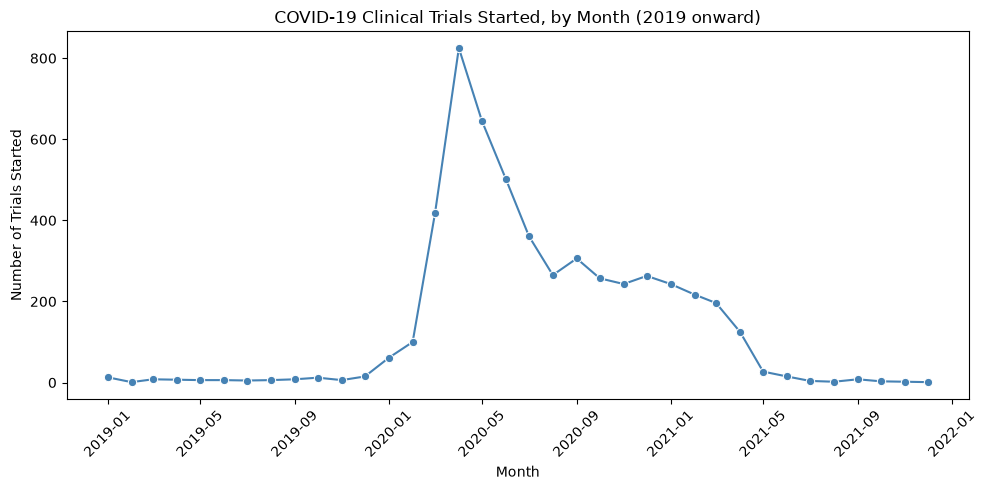

In [10]:
trend_data = con.execute("""
    SELECT 
        DATE_TRUNC('month', "Start Date") AS start_month,
        COUNT(*) AS trial_count
    FROM trials
    WHERE "Start Date" >= '2019-01-01'
    GROUP BY start_month
    ORDER BY start_month
""").df()

plt.figure(figsize=(10, 5))
sns.lineplot(data=trend_data, x='start_month', y='trial_count', marker='o', color='steelblue')
plt.title('COVID-19 Clinical Trials Started, by Month (2019 onward)')
plt.xlabel('Month')
plt.ylabel('Number of Trials Started')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
print(con.execute('SELECT MAX("Last Update Posted") FROM trials').df())
print(con.execute('SELECT MAX("First Posted") FROM trials').df())

  max("Last Update Posted")
0                2021-04-14
  max("First Posted")
0          2021-04-14


In [12]:
# “This dataset reflects trials registered as of [X date]; the drop-off after mid-2021 reflects the data collection cutoff,
#  not an actual decline in COVID-19 research activity.”

In [63]:
con.execute("""
CREATE OR REPLACE VIEW v_trials AS
SELECT
    "NCT Number"                                   AS nct_number,
    Title                                          AS title,
    Status                                         AS status,
    CASE WHEN "Study Type" LIKE 'Expanded Access%'
         THEN 'Expanded Access' ELSE "Study Type" END AS study_type,
    COALESCE(Gender, 'Missing')                    AS gender,
    "Enrollment"                                   AS enrollment,
    enrollment_bucket,
    "Start Date"                                   AS start_date,
    CASE WHEN "Completion Date" = DATE '2099-12-31'
         THEN NULL ELSE "Completion Date" END      AS completion_date,
    "First Posted"                                 AS first_posted,
    trial_duration_days,
    min_age,
    max_age,
    population_group,
    population_group LIKE '%Child%'                AS includes_children,
    "Completion Date" = DATE '2099-12-31' AS has_placeholder_completion_date
FROM trials
""")
print(con.execute("SELECT gender, COUNT(*) FROM v_trials GROUP BY gender").df())

    gender  count_star()
0   Female           162
1      All          5567
2     Male            44
3  Missing            10


In [69]:
import re, ollama
MODEL = 'qwen3.5:4b'

def build_schema(con):
    lines = []
    for (t,) in con.execute("SHOW TABLES").fetchall():
        if t == 'trials':          # raw table is hidden; the model only sees the view
            continue
        cols = con.execute(f"DESCRIBE {t}").fetchall()
        lines.append(f"{t}(" + ", ".join(f"{c[0]} {c[1]}" for c in cols) + ")")
    return "\n".join(lines)

def value_hints(con, max_vals=15):
    targets = [("v_trials", "status"), ("v_trials", "study_type"), ("v_trials", "gender"),
               ("v_trials", "population_group"), ("v_trials", "enrollment_bucket"),
               ("funders", "funder"), ("phases", "phase"),
               ("interventions", "intervention_type")]
    lines = []
    for t, c in targets:
        vals = [r[0] for r in con.execute(
            f'SELECT DISTINCT {c} FROM {t} WHERE {c} IS NOT NULL ORDER BY 1').fetchall()]
        if len(vals) <= max_vals:
            lines.append(f"{t}.{c}: {vals}")
    return "\n".join(lines)

SYSTEM = f"""You translate questions into DuckDB SQL for a COVID-19 clinical trials database.
Return ONLY one SQL SELECT statement. No explanation, no markdown.

SCHEMA:
{build_schema(con)}

VALUES (use these exactly):
{value_hints(con)}

RULES:
- Use v_trials for trial-level questions (one row per trial, ID column nct_number). Never use a table called trials.
- conditions, interventions, funders and phases have one row per trial+value. Join them to v_trials on nct_number. Only join conditions when the question is about conditions.
- Child tables repeat trials, so count with COUNT(DISTINCT nct_number). "How many" questions return one row with one number.
- Nearly every trial has condition 'covid-19'. Exclude it only when ranking or comparing conditions against each other.
- Never turn NULL into 0 (no COALESCE on ages or enrollment). Aggregates ignore NULLs. A NULL max_age means no upper age limit; min_age and max_age are blank when the registry only gives an age label.
- For age groups (children, adults, older adults) use population_group or includes_children, not min_age.
- gender values are All, Female, Male, Missing. "Female-only" means gender = 'Female'. Missing is its own category; never merge it into All.
- Match status words literally: "recruiting" means status = 'Recruiting' only.
- When comparing groups (for example conditions by median enrollment), only include groups with at least 20 trials (HAVING COUNT(DISTINCT ...) >= 20).
- Use MEDIAN for typical enrollment, because a few huge studies skew averages.
- Percentages within a group use SUM(...) OVER (PARTITION BY group) as the denominator. Always return the counts next to the percentages.
- The data ends on 2021-04-14. start_date can be a planned future date. For "latest" or "most recent" trial questions use first_posted. completion_date NULL means unknown or no end date.
- "Both A and B" (for example co-funded by A and B, or trials studying both condition A and B) means the trial is linked to both values in a child table. Wrap the grouping in a subquery so the result is ONE number: SELECT COUNT(*) FROM (SELECT nct_number FROM <child_table> WHERE <column> IN ('A','B') GROUP BY nct_number HAVING COUNT(DISTINCT <column>) = 2);
- has_placeholder_completion_date is true when the registry used 2099-12-31 as a "no end date" placeholder. completion_date is NULL for those trials.
- When asked WHICH group has the smallest, largest, most or fewest of something, return the group name together with the value. Never return only a MIN or MAX.
- - "Only" or "exclusively" children, adults or older adults means population_group = 'Child', 'Adult' or 'Older Adult' exactly (see VALUES). Do not add min_age or max_age conditions.

EXAMPLES:
Q: How many trials are in each phase?
SQL: SELECT phase, COUNT(DISTINCT nct_number) AS trials FROM phases GROUP BY phase ORDER BY trials DESC;
Q: Which conditions besides covid-19 have the most trials, and their median enrollment?
SQL: SELECT c.condition, COUNT(DISTINCT t.nct_number) AS trials, MEDIAN(t.enrollment) AS median_enrollment FROM v_trials t JOIN conditions c ON t.nct_number = c.nct_number WHERE c.condition != 'covid-19' GROUP BY c.condition HAVING COUNT(DISTINCT t.nct_number) >= 20 ORDER BY trials DESC LIMIT 10;
Q: What is the median enrollment of trials about covid-19?
SQL: SELECT MEDIAN(enrollment) AS median_enrollment FROM v_trials WHERE nct_number IN (SELECT nct_number FROM conditions WHERE condition = 'covid-19');
Q: How many trials are funded by both NIH and U.S. Fed?
SQL: SELECT COUNT(*) AS trials FROM (SELECT nct_number FROM funders WHERE funder IN ('NIH','U.S. Fed') GROUP BY nct_number HAVING COUNT(DISTINCT funder) = 2);
Q: What share of trials in each status are interventional vs observational?
SQL: SELECT status, study_type, COUNT(*) AS trials, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY status), 2) AS pct_of_status FROM v_trials GROUP BY status, study_type ORDER BY status, trials DESC;
Q: How many trials include children?
SQL: SELECT COUNT(*) AS trials FROM v_trials WHERE includes_children;
"""
print(f"prompt is about {len(SYSTEM)//4} tokens")
BLOCKED = re.compile(
    r"\b(insert|update|delete|drop|alter|create|copy|attach|detach|pragma|install|load|export|import|call|set)\b",
    re.I)

def extract_sql(text):
    m = re.search(r"```(?:sql)?\s*(.*?)```", text, re.S | re.I)
    return (m.group(1) if m else text).strip()

def is_safe(sql):
    body = sql.strip().rstrip(';')
    if ';' in body or not re.match(r"(?is)^\s*(select|with)\b", body):
        return False
    # remove quoted names/strings first, so a column like "Last Update Posted" isn't flagged
    scrubbed = re.sub(r'"[^"]*"|\'[^\']*\'', '', body)
    return not BLOCKED.search(scrubbed)

def ask(question, max_attempts=3, show_sql=True):
    messages = [{'role': 'system', 'content': SYSTEM},
                {'role': 'user', 'content': question}]
    error = None
    for attempt in range(1, max_attempts + 1):
        resp = ollama.chat(
            model=MODEL, messages=messages,
            options={'num_ctx': 6144, 'temperature': 0},
            think=(attempt == max_attempts),
            keep_alive='30m',
        )
        raw = resp['message']['content']
        sql = extract_sql(raw)
        if not is_safe(sql):
            error = "Rejected: only a single SELECT statement is allowed."
        else:
            try:
                df = con.execute(sql).df()
                if df.empty or df.isna().all().all():
                    error = ("The query ran but returned no rows or only NULLs. Check your joins "
                             "and filters. Use the child tables (conditions, phases, funders, "
                             "interventions) and match values exactly.")

                elif question.lower().startswith("how many") and len(df) > 1 and df.shape[1] == 1:
                    error = ("A 'how many' question must return ONE row with ONE number. "
                                "Wrap the grouping in a subquery and COUNT(*) it.")
                else:
                    if show_sql:
                        print(f"[attempt {attempt}]\n{sql}\n")
                    return df
            except Exception as e:
                error = str(e)
        messages += [{'role': 'assistant', 'content': raw},
                     {'role': 'user', 'content': f"That query failed: {error}\nReturn only the corrected SQL."}]
    print("No working query. Last error:", error)

prompt is about 1400 tokens


In [70]:
# EVAL = [
#     ("How many trials are observational studies?",
#      """SELECT COUNT(*) FROM trials WHERE "Study Type" = 'Observational'"""),
#     ("How many trials started before 2019?",
#      """SELECT COUNT(*) FROM trials WHERE "Start Date" < DATE '2019-01-01'"""),
#     ("What is the median trial duration in days?",
#      """SELECT MEDIAN(trial_duration_days) FROM trials"""),
#     ("How many trials does each funder type back?",
#      """SELECT funder, COUNT(DISTINCT nct_number) FROM funders GROUP BY funder"""),
#     ("What are the top 5 intervention types by number of trials?",
#      """SELECT intervention_type, COUNT(DISTINCT nct_number) FROM interventions
#         GROUP BY 1 ORDER BY 2 DESC LIMIT 5"""),
#     ("What is the median enrollment of Phase 3 trials?",
#      """SELECT MEDIAN("Enrollment") FROM trials
#         WHERE "NCT Number" IN (SELECT nct_number FROM phases WHERE phase = 'Phase 3')"""),
#     ("What is the median enrollment for each phase, excluding Not Applicable?",
#      """SELECT p.phase, MEDIAN(t."Enrollment") FROM trials t
#         JOIN phases p ON t."NCT Number" = p.nct_number
#         WHERE p.phase != 'Not Applicable' GROUP BY p.phase"""),
#     ("How many Industry-funded trials are in Phase 2?",
#      """SELECT COUNT(DISTINCT f.nct_number) FROM funders f
#         JOIN phases p ON f.nct_number = p.nct_number
#         WHERE f.funder = 'Industry' AND p.phase = 'Phase 2'"""),
#     ("How many trials study both covid-19 and depression?",
#      """SELECT COUNT(DISTINCT a.nct_number) FROM conditions a
#         JOIN conditions b ON a.nct_number = b.nct_number
#         WHERE a.condition = 'covid-19' AND b.condition = 'depression'"""),
#     ("Which condition other than covid-19 has the most trials?",
#      """SELECT condition FROM conditions WHERE condition != 'covid-19'
#         GROUP BY condition ORDER BY COUNT(DISTINCT nct_number) DESC LIMIT 1"""),
# ]



EVAL2 = [
      (
        "How many trials were posted in the first quarter of 2020 (between January 1, 2020 and March 31, 2020)?",
        """SELECT COUNT(DISTINCT "NCT Number") AS trials 
FROM trials 
WHERE "First Posted" BETWEEN DATE '2020-01-01' AND DATE '2020-03-31';"""
    ),
    (
        "Which status category has the highest average trial duration?",
        """SELECT Status, AVG(trial_duration_days) AS avg_duration 
FROM trials 
GROUP BY Status 
ORDER BY avg_duration DESC 
LIMIT 1;"""
    ),
    (
        "How many recruiting trials fall into the 'Small' enrollment bucket?",
        """SELECT COUNT(DISTINCT "NCT Number") AS trials 
FROM trials 
WHERE Status = 'Recruiting' AND enrollment_bucket = 'Small';"""
    ),
    (
        "What is the most common population group for trials that are backed by U.S. Fed funding?",
        """SELECT t.population_group, COUNT(DISTINCT t."NCT Number") AS trials 
FROM trials t 
JOIN funders f ON t."NCT Number" = f.nct_number 
WHERE f.funder = 'U.S. Fed' 
GROUP BY t.population_group 
ORDER BY trials DESC 
LIMIT 1;"""
    ),
    (
        "What percentage of trials with a 'Terminated' status were testing an Interventional study type?",
        """SELECT 
    CASE WHEN "Study Type" LIKE 'Expanded Access%' THEN 'Expanded Access' ELSE "Study Type" END AS clean_study_type, 
    COUNT(*) AS trials, 
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 2) AS pct_of_status 
FROM trials 
WHERE Status = 'Terminated' 
GROUP BY "Study Type";"""
    ),
    (
        "How many trials have an unknown or missing completion date where the status is still marked as Completed?",
        """SELECT COUNT(DISTINCT "NCT Number") AS trials 
FROM trials 
WHERE Status = 'Completed' AND ("Completion Date" IS NULL OR "Completion Date" = DATE '2099-12-31');"""
    ),
    (
        "Excluding the condition covid-19, list the top 3 conditions that have the highest number of Completed trials.",
        """SELECT c.condition, COUNT(DISTINCT t."NCT Number") AS trials 
FROM trials t 
JOIN conditions c ON t."NCT Number" = c.nct_number 
WHERE t.Status = 'Completed' AND c.condition != 'covid-19' 
GROUP BY c.condition 
HAVING COUNT(DISTINCT t."NCT Number") >= 20 
ORDER BY trials DESC 
LIMIT 3;"""
    ),
    (
        "Among completed trials, which funder is associated with the highest number of unique trials?",
        """SELECT f.funder, COUNT(DISTINCT t."NCT Number") AS trials 
FROM trials t 
JOIN funders f ON t."NCT Number" = f.nct_number 
WHERE t.Status = 'Completed' 
GROUP BY f.funder 
ORDER BY trials DESC 
LIMIT 1;"""
    ),
    (
        "Among trials with Phase 3, what percentage were interventional studies?",
        """SELECT 
    CASE WHEN t."Study Type" LIKE 'Expanded Access%' THEN 'Expanded Access' ELSE t."Study Type" END AS clean_study_type, 
    COUNT(DISTINCT t."NCT Number") AS trials,
    ROUND(100.0 * COUNT(DISTINCT t."NCT Number") / SUM(COUNT(DISTINCT t."NCT Number")) OVER(), 2) AS pct_of_phase
FROM trials t
JOIN phases p ON t."NCT Number" = p.nct_number
WHERE p.phase = 'Phase 3'
GROUP BY t."Study Type";"""
    ),
    (
        "What is the breakdown of study types (Interventional vs Observational) within the 'Mega' enrollment bucket?",
        """SELECT 
    CASE WHEN "Study Type" LIKE 'Expanded Access%' THEN 'Expanded Access' ELSE "Study Type" END AS clean_study_type, 
    COUNT(DISTINCT "NCT Number") AS trials 
FROM trials 
WHERE enrollment_bucket = 'Mega' 
GROUP BY "Study Type";"""
    )
]


def _v(x):
    if isinstance(x, float):
        x = round(x, 2)
        if x.is_integer():
            x = int(x)
    return str(x)

def norm(df):
    return sorted(tuple(sorted(_v(v) for v in r)) for r in df.itertuples(index=False))

def matches(got, expected):
    if got is None:
        return False
    if norm(got) == norm(expected):
        return True
    if expected.shape[1] == 1:   # the model may add extra columns (a count beside the answer)
        exp = sorted(_v(v) for v in expected.iloc[:, 0])
        return any(sorted(_v(v) for v in got[c]) == exp for c in got.columns)
    return False

def run_suite(suite):
    passed = 0
    for q, ref_sql in suite:
        expected = con.execute(ref_sql).df()
        got = ask(q, show_sql=False)
        ok = matches(got, expected)
        passed += ok
        print("PASS" if ok else "FAIL", "|", q)
        if not ok:
            print("  expected:", norm(expected)[:5])
            ask(q, show_sql=True)
    print(f"\n{passed} / {len(suite)}")

run_suite(EVAL2)

FAIL | How many trials were posted in the first quarter of 2020 (between January 1, 2020 and March 31, 2020)?
  expected: [('256',)]
[attempt 1]
SELECT COUNT(DISTINCT nct_number) AS trials FROM v_trials WHERE start_date >= '2020-01-01' AND start_date <= '2020-03-31';

PASS | Which status category has the highest average trial duration?
FAIL | How many recruiting trials fall into the 'Small' enrollment bucket?
  expected: [('0',)]
[attempt 1]
SELECT COUNT(DISTINCT nct_number) AS trials FROM v_trials WHERE status = 'Recruiting' AND enrollment_bucket = 'Small (<100)';

PASS | What is the most common population group for trials that are backed by U.S. Fed funding?
FAIL | What percentage of trials with a 'Terminated' status were testing an Interventional study type?
  expected: [('4', '5.41', 'Observational'), ('70', '94.59', 'Interventional')]
[attempt 1]
SELECT ROUND(100.0 * SUM(CASE WHEN study_type = 'Interventional' THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_interventional FROM v_trials W

In [71]:
q = "Among trials with Phase 3, what percentage were interventional studies?"
resp = ollama.chat(model=MODEL,
    messages=[{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': q}],
    options={'num_ctx': 6144, 'temperature': 0}, think=False, keep_alive='30m')
raw = resp['message']['content']
print(repr(raw))
sql = extract_sql(raw)
body = sql.strip().rstrip(';')
print("semicolon inside:", ';' in body)
print("starts with select/with:", bool(re.match(r"(?is)^\s*(select|with)\b", body)))
scrubbed = re.sub(r'"[^"]*"|\'[^\']*\'', '', body)
print("blocked word:", BLOCKED.search(scrubbed))

"SELECT ROUND(100.0 * SUM(CASE WHEN study_type = 'Interventional' THEN 1 ELSE 0 END) / COUNT(*) OVER (PARTITION BY phase), 2) AS pct_interventional FROM v_trials JOIN phases ON v_trials.nct_number = phases.nct_number WHERE phases.phase = 'Phase 3';"
semicolon inside: False
starts with select/with: True
blocked word: None


In [ ]:
def ask_debug(question, max_attempts=3):
    messages = [{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': question}]
    for attempt in range(1, max_attempts + 1):
        think = (attempt == max_attempts)
        resp = ollama.chat(model=MODEL, messages=messages,
                           options={'num_ctx': 6144, 'temperature': 0},
                           think=think, keep_alive='30m')
        raw = resp['message']['content']
sql = extract_sql(raw)
if not raw.strip():
    error = "Empty response. Return a single SQL SELECT statement."
elif not is_safe(sql):
    error = "Rejected: only a single SELECT statement is allowed."
else:
    ...  # the rest of the try/except stays as it is
            try:
                df = con.execute(sql).df()
                print(df)
                return df
            except Exception as e:
                error = str(e)
        print("ERROR:", error[:300])
        messages += [{'role': 'assistant', 'content': raw},
                     {'role': 'user', 'content': f"That query failed: {error}\nReturn only the corrected SQL."}]

ask_debug("Among trials with Phase 3, what percentage were interventional studies?")

--- attempt 1 | think=False ---
"SELECT ROUND(100.0 * SUM(CASE WHEN study_type = 'Interventional' THEN 1 ELSE 0 END) / COUNT(*) OVER (PARTITION BY phase), 2) AS pct_interventional FROM v_trials JOIN phases ON v_trials.nct_number = phases.nct_number WHERE phases.phase = 'Phase 3';"
ERROR: Binder Error: column "phase" must appear in the GROUP BY clause or must be part of an aggregate function.
Either add it to the GROUP BY list, or use "ANY_VALUE(phase)" if the exact value of "phase" is not important.

LINE 1: ...entional' THEN 1 ELSE 0 END) / COUNT(*) OVER (PARTITION BY phase), 2) AS
--- attempt 2 | think=False ---
"SELECT ROUND(100.0 * SUM(CASE WHEN t.study_type = 'Interventional' THEN 1 ELSE 0 END) / COUNT(*) OVER (PARTITION BY p.phase), 2) AS pct_interventional FROM v_trials t JOIN phases p ON t.nct_number = p.nct_number WHERE p.phase = 'Phase 3';"
ERROR: Binder Error: column "phase" must appear in the GROUP BY clause or must be part of an aggregate function.
Either add it to the GRO

In [ ]:
q = "Among trials with Phase 3, what percentage were interventional studies?"
resp = ollama.chat(model=MODEL,
    messages=[{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': q}],
    options={'num_ctx': 6144, 'temperature': 0}, think=True, keep_alive='30m')
print("content:", repr(resp['message']['content']))
print("thinking chars:", len(getattr(resp.message, 'thinking', None) or ''))
print("done_reason:", getattr(resp, 'done_reason', None),
      "| generated:", resp['eval_count'], "| prompt:", resp['prompt_eval_count'])

In [66]:
print(ask("How many trials exclusively enroll participants aged 65 and above?"))

[attempt 1]
SELECT COUNT(DISTINCT nct_number) AS trials FROM v_trials WHERE population_group = 'Older Adult' AND min_age >= 65 AND max_age IS NULL OR (min_age IS NULL AND max_age IS NULL);

   trials
0     558


In [67]:
import os
os.makedirs("prompts", exist_ok=True)
with open("prompts/system_prompt_v1.txt", "w", encoding="utf-8") as f:
    f.write(SYSTEM)

In [ ]:
print(ask("When is the last trial date?"))
print(ask("What is the median enrollment by condition, hypertension, diabetes, obesity, and depression?"))
print(ask("How many of the trials are suspended, terminated, or withdrawn?"))
print(ask("How many trials with conditions covid-19 are still recruiting?"))
print(ask("How many of the trials start before year 2019"))

[attempt 1]
SELECT MAX(t."First Posted") AS latest_date FROM trials t;

  latest_date
0  2021-04-14
[attempt 1]
SELECT c.condition, MEDIAN(t."Enrollment") AS median_enrollment FROM trials t JOIN conditions c ON t."NCT Number" = c.nct_number WHERE c.condition IN ('hypertension', 'diabetes', 'obesity', 'depression') GROUP BY c.condition ORDER BY median_enrollment DESC;

      condition  median_enrollment
0    depression              500.0
1  hypertension              340.0
2       obesity              198.0
3      diabetes              192.0
[attempt 1]
SELECT COUNT(DISTINCT t."NCT Number") AS count FROM trials t WHERE t.Status IN ('Suspended', 'Terminated', 'Withdrawn');

   count
0    208
[attempt 1]
SELECT COUNT(DISTINCT t."NCT Number") AS trial_count FROM trials t JOIN conditions c ON t."NCT Number" = c.nct_number WHERE c.condition = 'covid-19' AND t."Status" = 'Recruiting';

   trial_count
0         2248
[attempt 1]
SELECT COUNT(DISTINCT t."NCT Number") AS trial_count FROM trials t 

In [18]:
print(con.execute("""
    SELECT condition, COUNT(DISTINCT nct_number) AS trials
    FROM conditions WHERE condition ILIKE '%diabet%'
    GROUP BY condition ORDER BY trials DESC
""").df())

                                           condition  trials
0                                           diabetes      70
1                             diabetic macular edema       1
2                            diabetic kidney disease       1
3  diabetic patient (type 1,2, mody, secondary) o...       1
4                              pregnancy in diabetic       1
5                                        prediabetes       1
6                              non diabetic patients       1
7                             diabetes complications       1


In [19]:
print(con.execute("""
    SELECT COUNT(DISTINCT t."NCT Number") FROM trials t
    JOIN conditions c ON t."NCT Number" = c.nct_number
    WHERE c.condition = 'covid-19' AND t.Status = 'Recruiting'
""").df())

   count(DISTINCT t."NCT Number")
0                            2248


In [20]:
print(ask("How many trials are co-funded by the industry and the NIH"))
print(ask("How many of the trials recruit participants under 18 years old?"))
print(ask("How many of the trials have a placeholder date for a completion date?"))
print(ask("How many trials specifically recruit only female participants?"))
print(ask("List the top 5 study name with the highest enrollment"))

[attempt 1]
SELECT COUNT(DISTINCT t."NCT Number") AS co_funded_trials FROM trials t JOIN funders f ON t."NCT Number" = f.nct_number WHERE f.funder IN ('Industry', 'NIH') GROUP BY t."NCT Number" HAVING COUNT(DISTINCT f.funder) = 2;

    co_funded_trials
0                  1
1                  1
2                  1
3                  1
4                  1
5                  1
6                  1
7                  1
8                  1
9                  1
10                 1
11                 1
12                 1
13                 1
14                 1
15                 1
16                 1
17                 1
18                 1
19                 1
20                 1
21                 1
[attempt 1]
SELECT COUNT(DISTINCT t."NCT Number") AS recruiting_under_18 FROM trials t JOIN conditions c ON t."NCT Number" = c.nct_number WHERE (c.condition LIKE '%Child%' OR c.condition LIKE '%Older Adult%') AND (t.min_age < 18 OR t.max_age IS NULL) AND t.status = 'Recruiting';

   r

In [ ]:
print(ask("Compare the number of female-only and male-only trials. What is the percentage difference?"))
print(ask("What is the gender distribution among completed trials, and how does it compare with recruiting trials?"))
print(ask("What is the average minimum age and average maximum age of eligible participants?"))
print(ask("Can you determine how many trials exclusively enrolled participants aged 65 and above?"))
print(ask("How many trials had no recorded funder, and how did you determine that?"))
print(ask("Which condition has the highest number of recruiting trials?"))
print(ask("Which conditions are associated with both the smallest and largest median enrollment?"))

[attempt 2]
SELECT 
  (COUNT(DISTINCT CASE WHEN t.Gender = 'Female' THEN t."NCT Number" END) * 100.0 / COUNT(DISTINCT t."NCT Number")) - 
  (COUNT(DISTINCT CASE WHEN t.Gender = 'Male' THEN t."NCT Number" END) * 100.0 / COUNT(DISTINCT t."NCT Number")) AS percentage_difference
FROM trials t;

   percentage_difference
0               2.040463
[attempt 1]
SELECT 
    CASE 
        WHEN t.Status = 'Completed' THEN 'Completed'
        ELSE 'Recruiting'
    END AS trial_status,
    SUM(CASE WHEN t.Gender = 'Female' THEN 1 ELSE 0 END) AS female_count,
    SUM(CASE WHEN t.Gender = 'Male' THEN 1 ELSE 0 END) AS male_count,
    COUNT(DISTINCT t."NCT Number") AS total_trials
FROM trials t
WHERE (t.Status = 'Completed' OR t.Status = 'Recruiting')
GROUP BY trial_status
ORDER BY trial_status;

  trial_status  female_count  male_count  total_trials
0    Completed          33.0        16.0          1025
1   Recruiting          83.0        15.0          2805
[attempt 2]
SELECT 
  (COUNT(DISTINCT CASE WHE

In [29]:

print(con.execute("""WITH condition_medians AS (
    SELECT
        c.condition,
        MEDIAN(t."Enrollment") AS median_enrollment,
        COUNT(DISTINCT t."NCT Number") AS trial_count
    FROM trials t
    JOIN conditions c
        ON t."NCT Number" = c.nct_number
    WHERE c.condition != 'covid-19'
      AND t."Enrollment" IS NOT NULL
    GROUP BY c.condition
    HAVING COUNT(DISTINCT t."NCT Number") >= 20
)
SELECT 'largest median' AS result, condition,
       median_enrollment, trial_count
FROM condition_medians
ORDER BY median_enrollment DESC
LIMIT 1;


""").df())

           result                condition  median_enrollment  trial_count
0  largest median  cardiovascular diseases              900.0           33


In [ ]:
print(con.execute(""" SELECT
    t.Status,
    t.Gender,
    COUNT(DISTINCT t."NCT Number") AS trial_count
FROM trials t
WHERE t.Status IN ('Completed', 'Recruiting')
GROUP BY t.Status, t.Gender
ORDER BY t.Status, t.Gender;""").df())

       Status  Gender  trial_count
0   Completed     All          969
1   Completed  Female           33
2   Completed    Male           16
3   Completed     NaN            7
4  Recruiting     All         2707
5  Recruiting  Female           83
6  Recruiting    Male           15


In [31]:
print(ask("Compare completed and recruiting trials by gender eligibility category. Show the count and percentage for each category within each status, include missing gender values, and explain the denominator used."))

[attempt 2]
SELECT 
    t."Status",
    CASE 
        WHEN t.Gender = 'Female' THEN 'Female only'
        WHEN t.Gender = 'Male' THEN 'Male only'
        ELSE 'No restriction'
    END AS gender_category,
    COUNT(DISTINCT t."NCT Number") AS count,
    ROUND(100.0 * COUNT(DISTINCT t."NCT Number") / SUM(COUNT(DISTINCT t."NCT Number")) OVER (PARTITION BY t."Status"), 2) AS percentage
FROM trials t
WHERE t."Status" IN ('Completed', 'Recruiting')
GROUP BY t."Status", 
         CASE 
            WHEN t.Gender = 'Female' THEN 'Female only'
            WHEN t.Gender = 'Male' THEN 'Male only'
            ELSE 'No restriction'
         END
ORDER BY t."Status", count DESC;

       Status gender_category  count  percentage
0   Completed  No restriction    976       95.22
1   Completed     Female only     33        3.22
2   Completed       Male only     16        1.56
3  Recruiting  No restriction   2707       96.51
4  Recruiting     Female only     83        2.96
5  Recruiting       Male only    

In [32]:
print(ask("Among completed and recruiting trials, how many have missing gender values? Report them separately from trials whose gender category is All, and calculate the percentage of missing gender values within each status."))

[attempt 1]
SELECT 
    t."Status",
    COUNT(DISTINCT t."NCT Number") AS total_trials,
    SUM(CASE WHEN t.Gender IS NULL THEN 1 ELSE 0 END) AS missing_gender_count,
    (SUM(CASE WHEN t.Gender IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(DISTINCT t."NCT Number")) AS missing_gender_percentage
FROM trials t
WHERE t."Status" IN ('Completed', 'Recruiting')
GROUP BY t."Status"
ORDER BY t."Status";

       Status  total_trials  missing_gender_count  missing_gender_percentage
0   Completed          1025                   7.0                   0.682927
1  Recruiting          2805                   0.0                   0.000000


In [33]:
print(ask("Among completed and recruiting trials, report counts and percentages for each gender category, including All, Female, Male, and Missing as separate categories. Use total trials within each status as the denominator. Never group missing values into another category."))

[attempt 1]
SELECT 
    CASE 
        WHEN t.Gender = 'Female' THEN 'Female'
        WHEN t.Gender = 'Male' THEN 'Male'
        WHEN t.Gender = 'All' THEN 'All'
        ELSE 'Missing'
    END AS gender,
    COUNT(DISTINCT t."NCT Number") AS count,
    (COUNT(DISTINCT t."NCT Number") * 100.0 / SUM(COUNT(DISTINCT t."NCT Number")) OVER ()) AS percentage
FROM trials t
WHERE t.Status IN ('Completed', 'Recruiting')
GROUP BY gender
ORDER BY gender;

    gender  count  percentage
0      All   3676   95.979112
1   Female    116    3.028721
2     Male     31    0.809399
3  Missing      7    0.182768


In [34]:
con.execute("""WITH gender_counts AS (
    SELECT
        t.Status,
        CASE
            WHEN t.Gender = 'All' THEN 'All'
            WHEN t.Gender = 'Female' THEN 'Female'
            WHEN t.Gender = 'Male' THEN 'Male'
            WHEN t.Gender IS NULL THEN 'Missing'
            ELSE 'Other / Unknown'
        END AS gender,
        COUNT(DISTINCT t."NCT Number") AS trial_count
    FROM trials t
    WHERE t.Status IN ('Completed', 'Recruiting')
    GROUP BY
        t.Status,
        CASE
            WHEN t.Gender = 'All' THEN 'All'
            WHEN t.Gender = 'Female' THEN 'Female'
            WHEN t.Gender = 'Male' THEN 'Male'
            WHEN t.Gender IS NULL THEN 'Missing'
            ELSE 'Other / Unknown'
        END
)
SELECT
    Status,
    gender,
    trial_count,
    ROUND(
        trial_count * 100.0 /
        SUM(trial_count) OVER (PARTITION BY Status),
        2
    ) AS percentage
FROM gender_counts
ORDER BY Status, gender;""").df()

,Status,gender,trial_count,percentage
0,Completed,All,969,94.54
1,Completed,Female,33,3.22
2,Completed,Male,16,1.56
3,Completed,Missing,7,0.68
4,Recruiting,All,2707,96.51
5,Recruiting,Female,83,2.96
6,Recruiting,Male,15,0.53
